In [1]:
import pandas as pd

df=pd.read_csv('/kaggle/input/datasets/redwankarimsony/heart-disease-data/heart_disease_uci.csv')
print(df.head())

   id  age     sex    dataset               cp  trestbps   chol    fbs  \
0   1   63    Male  Cleveland   typical angina     145.0  233.0   True   
1   2   67    Male  Cleveland     asymptomatic     160.0  286.0  False   
2   3   67    Male  Cleveland     asymptomatic     120.0  229.0  False   
3   4   37    Male  Cleveland      non-anginal     130.0  250.0  False   
4   5   41  Female  Cleveland  atypical angina     130.0  204.0  False   

          restecg  thalch  exang  oldpeak        slope   ca  \
0  lv hypertrophy   150.0  False      2.3  downsloping  0.0   
1  lv hypertrophy   108.0   True      1.5         flat  3.0   
2  lv hypertrophy   129.0   True      2.6         flat  2.0   
3          normal   187.0  False      3.5  downsloping  0.0   
4  lv hypertrophy   172.0  False      1.4    upsloping  0.0   

                thal  num  
0       fixed defect    0  
1             normal    2  
2  reversable defect    1  
3             normal    0  
4             normal    0  


In [2]:
print("Missing Values:")
display(df.isnull().sum().sort_values(ascending=False))
print("================================================================")
missing_data_cols = df.isnull().sum()[df.isnull().sum() > 0].index.tolist()
print("Columns with Missing Values:")
display(missing_data_cols)

Missing Values:


ca          611
thal        486
slope       309
fbs          90
oldpeak      62
trestbps     59
exang        55
thalch       55
chol         30
restecg       2
cp            0
dataset       0
id            0
age           0
sex           0
num           0
dtype: int64

Columns with Missing Values:


['trestbps',
 'chol',
 'fbs',
 'restecg',
 'thalch',
 'exang',
 'oldpeak',
 'slope',
 'ca',
 'thal']

In [3]:
cat_cols=['sex','cp','fbs','restecg','exang','slope','thal']
bool_cols=['fbs','exang']
numeric_cols=['age','trestbps','chol','thalch','oldpeak','ca'] #discrete si continue
# print the cat_cols,bool_cols,numeric_cols
print('Categorical Variables:',cat_cols)
print('Binary Variables:', bool_cols)
print('Numeric Variables:', numeric_cols)

Categorical Variables: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']
Binary Variables: ['fbs', 'exang']
Numeric Variables: ['age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca']


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
#preprocessing
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.impute import SimpleImputer,KNNImputer

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import GridSearchCV, train_test_split

# Machine Learning
from sklearn.model_selection import train_test_split
# For Classification tasks
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier,GradientBoostingClassifier,RandomForestRegressor
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.naive_bayes import GaussianNB
from lightgbm import LGBMClassifier
from sklearn.model_selection import cross_val_score

# import pipeline
from sklearn.pipeline import Pipeline
import random
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
# metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_score, recall_score
from sklearn.metrics import f1_score

from sklearn.preprocessing import QuantileTransformer
from sklearn.preprocessing import PowerTransformer
from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline
import random
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
# metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import f1_score
# Remove Warnings
import warnings
warnings.filterwarnings('ignore')
# Disable LightGBM warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", message="No further splits with positive gain")
np.seterr(all="ignore")

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

In [5]:
def impute_categorical_value(missing_col, encoders=None):
    if encoders is None:
        encoders = {}
    
    df_null=df[df[missing_col].isnull()] #randuri care au goluri
    df_not_null=df[df[missing_col].notnull()] #randuri care nu au goluri
    #features si target pentru antrenament
    x=df_not_null.drop(missing_col, axis=1) #toate coloanele din randurile care nu au goluri vor folosi ca features
    y=df_not_null[missing_col] #coloana tinta pe care vrem sa o anticipam

    other_missing_cols=[col for col in missing_data_cols if col !=missing_col]
    #vrem sa stim care sunt celelalte coloane lipsa, pentru a le completa, aî să nu crape modelul 
    #vor fi completate temporar de IterativeImputer - folosind aproximari statistice / bazata pe un regresor intern
    #label_encoder= LabelEncoder()

    #transformam textele/stringurile in valori numerice
    
    for col in x.columns:
        if x[col].dtype in ['object', 'category']:
            le=LabelEncoder()
            x[col]=le.fit_transform(x[col])
            encoders[col] = le
            
    if missing_col in bool_cols:
        le_y = LabelEncoder()
        y = le_y.fit_transform(y)
        encoders[f'target_{missing_col}'] = le_y
        # y=label_encoder.fit_transform(y)  #valorile, coloanele goale sunt tinta/ce vrem sa prezicem acum

    iterative_imputer=IterativeImputer(estimator=RandomForestRegressor(random_state=42), add_indicator=True)

    
    for col in other_missing_cols:
        if x[col].isnull().sum() > 0 :
            x[col]=iterative_imputer.fit_transform(x[col].values.reshape(-1, 1))[:, 0]
    #Iterative Imputer asteapta la intrare un tabel bidimensional, de aceea aplicam reshape, ca sa obtinem o matrice cu o coloana (o linie)
    #chiar daca in x datele sunt tabulare, prin extractie fiecare coloana reprezinta o structura unidimensionala, ceea ce nu se potriveste

    x_train, x_test, y_train, y_test=train_test_split(x, y, test_size=0.2, random_state=42)
    
    #pentru aceste valori categorice vrem sa stabilim clasa din care fac parte valorile lipsa
    rf_classifier=RandomForestClassifier()
    rf_classifier.fit(x_train, y_train)
    

    print(
      f"Coloana '{missing_col}' a fost completată cu o acuratețe"
      f" de:"
      f" {round(accuracy_score(y_test, rf_classifier.predict(x_test)) * 100, 2)}%\n"
     )

    #aplicam modelul antrenat pe randurile cu valori lipsa
    #acum completam datele
    x=df_null.drop(missing_col, axis=1)

    for col in x.columns:
        if x[col].dtype in ['object', 'category']:
            if x[col].isnull().any():
                x[col] = x[col].fillna(encoders[col].classes_[0])
            x[col]=encoders[col].transform(x[col])

    for col in other_missing_cols:
        if x[col].isnull().sum() > 0 :
            x[col]=iterative_imputer.transform(x[col].values.reshape(-1, 1))[:, 0]
    
    
    if len(df_null)>0:
        df_null[missing_col]=rf_classifier.predict(x)
        if missing_col in bool_cols:
            df_null[missing_col] = df_null[missing_col].map({0: False, 1: True})
            
    return pd.concat([df_not_null, df_null])[missing_col], encoders
            

In [6]:
def impute_continuous_value(missing_col, encoders=None):
    if encoders is None:
        encoders = {}
        
    df_null=df[df[missing_col].isnull()]
    df_not_null=df[df[missing_col].notnull()]
    x=df_not_null.drop(missing_col, axis=1)
    y=df_not_null[missing_col]

    other_missing_cols=[col for col in missing_data_cols if col!=missing_col] #vrem sa stim celelalte coloane lipsa
    
    
    # encoders = {}
    for col in x.columns:
        if x[col].dtype in ['object', 'category']:
            le=LabelEncoder()
            x[col]=le.fit_transform(x[col])
            encoders[col] = le

    iterative_imputer=IterativeImputer(estimator=RandomForestRegressor(random_state=42), add_indicator=True)

    #completam celelalte coloane cu lipsuri
    for col in other_missing_cols:
        if x[col].isnull().sum() > 0 :
            x[col]=iterative_imputer.fit_transform(x[col].values.reshape(-1, 1))[:, 0]

    x_train, x_test, y_train, y_test=train_test_split(x, y, test_size=0.2, random_state=42)
    
    #pentru aceste valori categorice vrem sa stabilim clasa din care fac parte valorile lipsa
    rf_regressor=RandomForestRegressor(random_state=42)
    rf_regressor.fit(x_train, y_train)
    y_pred=rf_regressor.predict(x_test)

    print("MAE =", mean_absolute_error(y_test, y_pred), "\n")
    print("RMSE =", np.sqrt(mean_squared_error(y_test, y_pred)), "\n")
    print("R2 =", r2_score(y_test, y_pred), "\n")
    

    #aplicam modelul antrenat pe randurile cu valori lipsa
    #acum completam datele
    x=df_null.drop(missing_col, axis=1)

    for col in x.columns:
        if x[col].dtype in ['object', 'category']:
            if x[col].isnull().any():
              x[col] = x[col].fillna(encoders[col].classes_[0])
                
            x[col]=encoders[col].transform(x[col])

    for col in other_missing_cols:
        if x[col].isnull().sum() > 0 :
            x[col]=iterative_imputer.transform(x[col].values.reshape(-1, 1))[:, 0]
    
    
    if len(df_null)>0:
        df_null[missing_col]=rf_regressor.predict(x)

            
    return pd.concat([df_not_null, df_null])[missing_col], encoders
            
      
    

In [7]:
for cols in missing_data_cols:
    print(f"\033[1;38;5;54m{'=' * 55}\033[0m")
    print(f"\033[1;38;5;54m  Missing Values: {cols}\033[0m")
    print(f"\033[1;38;5;54m{'=' * 55}\033[0m")
    print(
        'Missing Percentage:',
        str(round(df[cols].isnull().sum() / len(df) * 100, 2)) + '%'
    )
    print()

    encoders={}
    if cols in cat_cols:
        df[cols], encoders = impute_categorical_value(cols, encoders)

    elif cols in numeric_cols:
        if cols != 'num':
            df[cols], encoders = impute_continuous_value(cols, encoders)

    else:
        pass

  Missing Values: trestbps
Missing Percentage: 6.41%

MAE = 13.366763005780346 

RMSE = 17.395234564360806 

R2 = 0.05520328228326754 

  Missing Values: chol
Missing Percentage: 3.26%

MAE = 45.44415730337079 

RMSE = 63.72684453671578 

R2 = 0.6782908042630391 

  Missing Values: fbs
Missing Percentage: 9.78%

Coloana 'fbs' a fost completată cu o acuratețe de: 78.31%

  Missing Values: restecg
Missing Percentage: 0.22%

Coloana 'restecg' a fost completată cu o acuratețe de: 66.3%

  Missing Values: thalch
Missing Percentage: 5.98%

MAE = 16.778439306358383 

RMSE = 21.660901899465447 

R2 = 0.31775182202299157 

  Missing Values: exang
Missing Percentage: 5.98%

Coloana 'exang' a fost completată cu o acuratețe de: 78.03%

  Missing Values: oldpeak
Missing Percentage: 6.74%

MAE = 0.568046511627907 

RMSE = 0.7986303682657447 

R2 = 0.39235547861101805 

  Missing Values: slope
Missing Percentage: 33.59%

Coloana 'slope' a fost completată cu o acuratețe de: 65.85%

  Missing Values: c

In [8]:
#analizam factorii de risc - high blood pressure - in corelatie cu genul
print("Resting Blood Pressure Distribution by Gender")
trestbps_sex_counts=df.groupby('trestbps')['sex'].value_counts().reset_index(name='Count')
display(trestbps_sex_counts.head(20))
# display(trestbps_sex_counts.tail(20))

Resting Blood Pressure Distribution by Gender


,trestbps,sex,Count
0,0.0,Male,1
1,80.0,Male,1
2,92.0,Male,1
3,94.0,Female,1
4,94.0,Male,1
5,95.0,Male,5
6,95.0,Female,1
7,96.0,Male,1
8,98.0,Male,1
9,100.0,Male,11


In [9]:
#binning
#discretizam valorile continue ale acestei trasaturi -> intelegerea mai usoara a pragurilor de risc

bins = [0, 90, 120, 140, 160, float('inf')]
labels = ['hipotensiune', 'normal', 'prehipertensiune', 'hipertensiune_stadiu1', 'hipertensiune_severa']

df['trestbps_bins'] = pd.cut(df['trestbps'], bins=bins, labels=labels)

df.head()

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num,trestbps_bins
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0,hipertensiune_stadiu1
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2,hipertensiune_stadiu1
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1,normal
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0,prehipertensiune
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0,prehipertensiune


Valori lipsa in trestbps_bins: 1
Distribution of trestbps:


<Axes: xlabel='trestbps', ylabel='Count'>

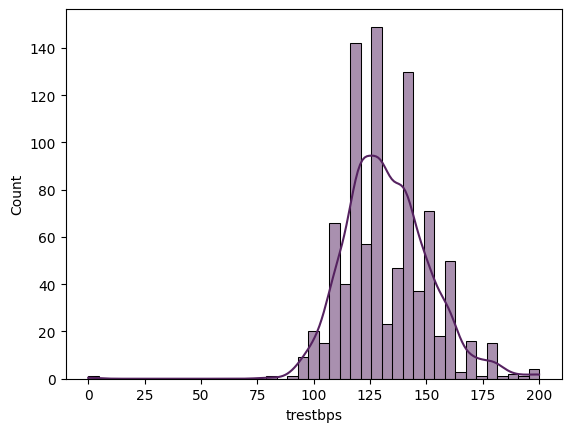

In [10]:
print("Valori lipsa in trestbps_bins:", df['trestbps_bins'].isnull().sum())

print("Distribution of trestbps:")
sns.histplot(df, x='trestbps', kde=True, color="#552260")

In [12]:
#distributie trestbps_bins
print("Resting Blood Pressure Distribution by Gender")
trestbps_sex_counts = df.groupby('trestbps_bins')['sex'].value_counts().reset_index(name='Count')
display(trestbps_sex_counts)

#distributie pe gen

print("Resting Blood Pressure Distribution by Gender")
fig = px.histogram(df, x='trestbps', color='sex', color_discrete_sequence=["#552260", "#FF00FF", "#9B5AAA"])
fig.show()

Resting Blood Pressure Distribution by Gender


,trestbps_bins,sex,Count
0,hipotensiune,Male,1
1,hipotensiune,Female,0
2,normal,Male,224
3,normal,Female,69
4,prehipertensiune,Male,299
5,prehipertensiune,Female,80
6,hipertensiune_stadiu1,Male,169
7,hipertensiune_stadiu1,Female,34
8,hipertensiune_severa,Male,32
9,hipertensiune_severa,Female,11


Resting Blood Pressure Distribution by Gender


In [13]:
#analizam factorii de risc - colesterolul - in corelatie cu genul
print("Chol Distribution by Gender")
chol_sex_counts=df.groupby('chol')['sex'].value_counts().reset_index(name='Count')
# display(chol_sex_counts.head(20))
display(chol_sex_counts.tail(10))

chol_stats = df['chol'].describe().to_frame('Value')
print("Statistical Summary of chol:")
display(chol_stats)

print("Cholesterol Distribution by Gender")
fig = px.histogram(df, x='chol', color='sex', color_discrete_sequence=["#552260", "#FF00FF", "#9B5AAA"])
fig.show()

Chol Distribution by Gender


,chol,sex,Count
338,412.0,Male,1
339,417.0,Female,1
340,458.0,Male,1
341,466.0,Male,1
342,468.0,Female,1
343,491.0,Male,1
344,518.0,Male,1
345,529.0,Male,1
346,564.0,Female,1
347,603.0,Male,1


Statistical Summary of chol:


,Value
count,920.000000
mean,200.418478
std,109.358125
min,0.000000
25%,177.750000
50%,224.000000
75%,267.250000
max,603.000000


Cholesterol Distribution by Gender


In [14]:
print("Heart Disease Categories")
bins = [0, 1, 2, 3, 4]
labels = ['No-Heart-Disease', 'Mild-Heart-Disease', 'Moderate-Heart-Disease', 'Severe-Heart-Disease']
# Create a new column based on the num values
df['num_bins'] = pd.cut(df['num'], bins=bins, labels=labels)
# Display the updated dataset
display(df.head())

Heart Disease Categories


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num,trestbps_bins,num_bins
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0,hipertensiune_stadiu1,NaN
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2,hipertensiune_stadiu1,Mild-Heart-Disease
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1,normal,No-Heart-Disease
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0,prehipertensiune,NaN
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0,prehipertensiune,NaN


In [ ]:
# Impute missing values in num_bins using the mode
df['num_bins'].fillna(df['num_bins'].mode()[0], inplace=True)
# Display the updated dataset
print("Dataset after imputing missing values in num_bins:")
display(df.head())

In [ ]:
print("Value Counts of num:")
display(df['num'].value_counts())

In [ ]:
print("Value Counts of num by Gender:")
num_sex_counts = (df.groupby('num')['sex'].value_counts().reset_index(name='Count'))
display(num_sex_counts)

In [15]:
# verificam randurile unde trestbps (static blood pressure) este 0
print("Rows where trestbps is 0:")
display(df[df['trestbps'] == 0])
# Remove rows where trestbps is 0
df = df[df['trestbps'] != 0]
# Display the updated dataset
print("Dataset after removing rows where trestbps is 0:")
display(df.head())

Rows where trestbps is 0:


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num,trestbps_bins,num_bins
753,754,55,Male,VA Long Beach,non-anginal,0.0,0.0,False,normal,155.0,False,1.5,flat,1.24,reversable defect,3,NaN,Moderate-Heart-Disease


Dataset after removing rows where trestbps is 0:


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num,trestbps_bins,num_bins
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0,hipertensiune_stadiu1,NaN
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2,hipertensiune_stadiu1,Mild-Heart-Disease
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1,normal,No-Heart-Disease
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0,prehipertensiune,NaN
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0,prehipertensiune,NaN


In [ ]:
#vom folosi transformari liniare pentru a transpune datele intr o distributie cunoscuta, simetrica => clopotul lui Gauss
#vrem sa nu ne lasam influentati de outliers, sau de pacientii cu date 'exceptie' care pot deveni generali, desi nu e cazul
#asa ca incercam sa aducem datele in aceeasi zona de medie si de varianta

#aceste transformari ajuta exclusiv modelele care se bazeaza pe calcul de distante (SVM, K-means, Logistic Regression)
#nu influenteaza (semnificativ) modelele bazate pe arbori

#transformă datele asimetrice într-o distribuție normală (clopot) și stabilizează varianța.
#nu functioneaza pe valori negative, sau nule
# pt_boxcox=PowerTransformer(standardize=True)
# df[numeric_cols]=pt_boxcox.fit_transform(df[numeric_cols])

#similar cu Box Cox, normalizeaza si stabilizeaza datele(corecteaza asimetria)
#avantaj - suporta si date negative sau nule, aplicabil pe scenarii reale
# pt_yeojohnson=PowerTransformer(standardize=True)
# df[numeric_cols]=pt_yeojohnson.fit_transform(df[numeric_cols])

# forțează valorile să urmeze o distribuție normală (sau uniformă) pe baza rangurilor și a percentilelor.
# estompează impactul valorilor extreme (outliers), dar poate schimba distanțele dintre valori.
# qt_normal=QuantileTransformer(output_distribution='normal', random_state=42)
# df[numeric_cols]=qt_normal.fit_transform(df[numeric_cols])

In [16]:
import joblib
X=df.drop(['id','num','dataset', 'num_bins'], axis=1)
y=df['num'].astype(int)
random_state=42

# impartire stratificata pe clase(y) pentru a ne asigura ca se regasesc in aceeasi proportie etichetele
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42,stratify=y)

#fit_transform -> invata si aplica
#transform -> aplica ce a invatat deja

cols_to_encode = ['sex','cp','fbs','restecg','exang','slope','thal','trestbps_bins']
for col in cols_to_encode:
    le = LabelEncoder()
    if col in encoders:
        X_train[col]=encoders[col].transform(X_train[col])
        X_test[col]=encoders[col].transform(X_test[col])
    else:
        X_train[col] = le.fit_transform(X_train[col])
        encoders[col]=le
        X_test[col] = le.transform(X_test[col])

numeric_cols=[col for col in numeric_cols if col not in ['num', 'id']]
scalar=StandardScaler()
X_train[numeric_cols]=scalar.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = scalar.transform(X_test[numeric_cols])

pt_yeojohnson = PowerTransformer(standardize=True)
X_train[numeric_cols] = pt_yeojohnson.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = pt_yeojohnson.transform(X_test[numeric_cols])

models = {
    'Logistic Regression': (LogisticRegression(random_state=42), {}),
    'KNN': (KNeighborsClassifier(), {'model__n_neighbors': [10, 30]}),
    'SVC': (SVC(random_state=42), {'model__gamma': ['scale', 'auto']}),
    'DecisionTreeClassifier': (DecisionTreeClassifier(random_state=42), {'model__max_depth': [5, 10, 15]}),
    'RandomForestClassifier': (RandomForestClassifier(random_state=42), {'model__n_estimators': [100, 200, 300], 'model__max_depth': [5, 10, 15]}),
    'GradientBoostingClassifier': (GradientBoostingClassifier(random_state=42), {'model__learning_rate': [0.1, 0.01, 0.001]}),
    'AdaBoostClassifier': (AdaBoostClassifier(random_state=42), {'model__n_estimators': [50, 100, 200]}),
    'XGBClassifier': (XGBClassifier(random_state=42), {'model__max_depth': [3, 4, 5]}),
    'Naive Bayes': (GaussianNB(), {})
}

best_model=None
best_accuracy=0
for name,(models,params) in models.items():
    pipeline=Pipeline(steps=[
        ('model',models)
])
    # Apply the cross validation score
    scores=cross_val_score(pipeline, X_train, y_train,cv=5, verbose=0)
    # mean_accuracy
    mean_accuracy=scores.mean()
    # predict the pipeline
    pipeline.fit(X_train,y_train)
    # Train the pipeline
    y_pred=pipeline.predict(X_test)
    accuracy=accuracy_score(y_test,y_pred)
    precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    # print the evaluation metrics
    print('Model', name)
    print('Cross_validation accuracy', mean_accuracy)
    print('accuracy', accuracy)
    print('Precision (weighted):', precision)
    print('Recall (weighted):', recall)
    print('\n')

    # Evaluate the model
    if accuracy > best_accuracy:
       best_accuracy = accuracy
       best_model = pipeline
# print the best model
print("Best Model is:", best_model)
joblib.dump(best_model, 'model_random_forest.pkl')
joblib.dump(scalar, 'scaler.pkl')
joblib.dump(pt_yeojohnson, 'yeojohnson.pkl')
joblib.dump(encoders, 'encoders.pkl')

Model Logistic Regression
Cross_validation accuracy 0.6204081632653062
accuracy 0.6358695652173914
Precision (weighted): 0.6168642951251647
Recall (weighted): 0.6358695652173914


Model KNN
Cross_validation accuracy 0.5918367346938774
accuracy 0.657608695652174
Precision (weighted): 0.6100331386725992
Recall (weighted): 0.657608695652174


Model SVC
Cross_validation accuracy 0.6340136054421768
accuracy 0.6956521739130435
Precision (weighted): 0.664005529155749
Recall (weighted): 0.6956521739130435


Model DecisionTreeClassifier
Cross_validation accuracy 0.6
accuracy 0.6521739130434783
Precision (weighted): 0.6530363272311213
Recall (weighted): 0.6521739130434783


Model RandomForestClassifier
Cross_validation accuracy 0.6653061224489796
accuracy 0.7608695652173914
Precision (weighted): 0.7441289395135264
Recall (weighted): 0.7608695652173914


Model GradientBoostingClassifier
Cross_validation accuracy 0.6666666666666666
accuracy 0.6902173913043478
Precision (weighted): 0.69234410467958

['encoders.pkl']

In [17]:
print(X_train.columns)
feature_names = list(X_train.columns)
joblib.dump(feature_names, 'feature_names.pkl')

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'trestbps_bins'],
      dtype='object')


['feature_names.pkl']

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

name='RandomForestClassifier'
best_rf = RandomForestClassifier(n_estimators=200, max_depth=15, random_state=42)
best_rf.fit(X_train, y_train)

y_pred_rf = best_rf.predict(X_test)


cm = confusion_matrix(y_test, y_pred_rf)

accuracy=accuracy_score(y_test,y_pred_rf)
precision = precision_score(y_test, y_pred_rf, average='weighted', zero_division=0)
recall = recall_score(y_test, y_pred_rf, average='weighted', zero_division=0)
    
print('Model', name)
print('Cross_validation accuracy', mean_accuracy)
print('accuracy', accuracy)
print('Precision (weighted):', precision)
print('Recall (weighted):', recall)
print('\n')



plt.figure(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=best_rf.classes_)
disp.plot(cmap=plt.cm.Purples, values_format='d')
plt.title('Matrice de Confuzie - RandomForestClassifier')
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

name='XGBClassifier'
best_xg = XGBClassifier(max_depth=5, random_state=42)
best_xg.fit(X_train, y_train)

y_pred_xg = best_xg.predict(X_test)


cm = confusion_matrix(y_test, y_pred_xg)

accuracy=accuracy_score(y_test,y_pred_xg)
precision = precision_score(y_test, y_pred_xg, average='weighted', zero_division=0)
recall = recall_score(y_test, y_pred_xg, average='weighted', zero_division=0)
    
print('Model', name)
print('Cross_validation accuracy', mean_accuracy)
print('accuracy', accuracy)
print('Precision (weighted):', precision)
print('Recall (weighted):', recall)
print('\n')



plt.figure(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=best_rf.classes_)
disp.plot(cmap=plt.cm.Purples, values_format='d')
plt.title('Matrice de Confuzie - RandomForestClassifier')
plt.show()

In [ ]:
#Hyperparameter tuning

#completeaza valorile numerice lipsa cu mediana (valoarea de mijloc) a trasaturii respective, apoi normalizeaza trasaturile la medie 0 si deviatie 1
numeric_transformer = Pipeline(steps=[('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])

#completeaza valorile categorice lipsa cu cea mai frecventa valoare a trasaturii respective, apoi transforma categoriile in continut binar
categorical_transformer = Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

#definim pe ce atribute vrem sa aplicam transformari, si ce trasnformari mai exact
preprocessor = ColumnTransformer(transformers=[('numeric', numeric_transformer, ['age', 'trestbps', 'thalch']), ('cat', categorical_transformer, ['sex', 'cp', 'fbs', 'restecg', 'exang', 'trestbps_bins'])])
selector = SelectKBest(f_classif) #alegem cele mai relevante 10 caracteristici ale setului de date
#scorul prin care selectam se refera la influenta (f_classif => ANOVA analysis of variance) pe care o are o trasatura respectiva in a stabili eticheta finala

X = df.drop(['id', 'num','dataset', 'num_bins',], axis=1)
y = df['num']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.columns)
# models = {
#     'Logistic Regression': (LogisticRegression(random_state=42, max_iter=1000), {'model__C': [0.01, 0.1, 1, 10], 'model__solver': ['liblinear', 'lbfgs'], 'model__penalty': ['l2']}),
#     'KNN': (KNeighborsClassifier(), {'model__n_neighbors': [10, 30]}),
#     'SVC': (SVC(random_state=42), {'model__gamma': ['scale', 'auto']}),
#     'DecisionTreeClassifier': (DecisionTreeClassifier(random_state=42), {'model__max_depth': [5, 10, 15]}),
#     'RandomForestClassifier': (RandomForestClassifier(random_state=42), {'model__n_estimators': [100, 200, 300], 'model__max_depth': [5, 10, 15]}),
#     'GradientBoostingClassifier': (GradientBoostingClassifier(random_state=42), {'model__learning_rate': [0.1, 0.01, 0.001]}),
#     'AdaBoostClassifier': (AdaBoostClassifier(random_state=42), {'model__n_estimators': [50, 100, 200]}),
#     'XGBClassifier': (XGBClassifier(random_state=42), {'model__max_depth': [3, 4, 5]}),
#     'Naive Bayes': (GaussianNB(), {'model__var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6, 1e-5]})
# }


models = {
    'Logistic Regression': (
        LogisticRegression(random_state=42, max_iter=1000),
        {
            'selector__k': [10, 15, 20],
            'model__C': [0.01, 0.1, 1, 10],
            'model__solver': ['liblinear', 'lbfgs']
        }
    ),

    'RandomForestClassifier': (
        RandomForestClassifier(random_state=42),
        {
            'selector__k': [10, 15, 20],
            'model__n_estimators': [100, 200],
            'model__max_depth': [5, 10, 15]
        }
    ),

    'GradientBoostingClassifier': (
        GradientBoostingClassifier(random_state=42),
        {
            'selector__k': [10, 15, 20],
            'model__learning_rate': [0.1, 0.01]
        }
    )
}
best_model_name, best_model_accuracy = None, 0,
for name, (model, params_grid) in models.items():
    pipeline = Pipeline([('preprocessor', preprocessor), ('selector', selector), ('model', model)]) #preprocesare date => selectie caracteristici => trimitere catre model
    grid_search = GridSearchCV(estimator=pipeline, param_grid=params_grid, cv=5, n_jobs=1, verbose=0)
    grid_search.fit(X_train, y_train)
    y_pred = grid_search.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    print(f"{name}")
    print(f" Accuracy : {accuracy:.4f}")
    print(f"Best hyperparameters: {grid_search.best_params_}")
    print("============================================================")
    if accuracy > best_model_accuracy:
        best_model_accuracy, best_model_name = accuracy, name
print(f"The best model is {best_model_name} with an accuracy of {best_model_accuracy}")


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score
import matplotlib.pyplot as plt

#obiectul grid_search conține preprocesarea, selectorul și modelul
best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)

    print('Model: Random Forest (Optimizat)')
print('accuracy:', accuracy)
print('Precision (weighted):', precision)
print('Recall (weighted):', recall)
print('\n')

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))


disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=sorted(y_test.unique()))
disp.plot(cmap=plt.cm.Purples, values_format='d')
plt.title('Matrice de Confuzie - Random Forest')
plt.show()

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

df["target"] = (df["num"] != 0).astype(int)

X = df.drop(["num", "target", "id", "dataset", "num_bins"], axis=1)
y = df["target"]


X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42, stratify=y)

numeric_features = ["age", "trestbps", "thalch"]
categorical_features = ["sex", "cp", "fbs", "restecg", "exang", "trestbps_bins"]

numeric_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="median")),("scaler", StandardScaler())])

categorical_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="most_frequent")),("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])

preprocessor = ColumnTransformer(
    transformers=[("num", numeric_transformer, numeric_features),("cat", categorical_transformer, categorical_features)])


models = {
    "RandomForest": (
        RandomForestClassifier(class_weight="balanced", random_state=42),
        {
            "model__n_estimators": [100, 200],
            "model__max_depth": [5, 10, 15]
        }
    ),

    "GradientBoosting": (
        GradientBoostingClassifier(random_state=42),
        {
            "model__learning_rate": [0.1, 0.01],
            "model__max_depth": [3, 5]
        }
    ),

    "XGBoost": (
        XGBClassifier(random_state=42, eval_metric="logloss"),
        {
            "model__max_depth": [3, 4, 5],
            "model__learning_rate": [0.1, 0.01]
        }
    )
}


best_model_name = None
best_auc = 0

for name, (model, params) in models.items():

    pipeline = Pipeline([("preprocessor", preprocessor),("model", model))

    grid = GridSearchCV(estimator=pipeline,param_grid=params,cv=5,n_jobs=1,verbose=0)

    grid.fit(X_train, y_train)

    y_pred = grid.predict(X_test)
    y_prob = grid.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)

    print(f"\n{name}")
    print(f"Accuracy: {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall: {rec:.4f}")
    print(f"F1-score: {f1:.4f}")
    print(f"ROC-AUC: {auc:.4f}")
    print(f"Best params: {grid.best_params_}")
    print("====================================")

    if auc > best_auc:
        best_auc = auc
        best_model_name = name

print(f"\nBest clinical model: {best_model_name} (AUC={best_auc:.4f})")


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score
import matplotlib.pyplot as plt

#obiectul grid_search conține preprocesarea, selectorul și modelul
best_model = grid.best_estimator_

y_pred = best_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)

print('Model: Random Forest (Optimizat)')
print('accuracy:', accuracy)
print('Precision (weighted):', precision)
print('Recall (weighted):', recall)
print('\n')

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))


disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=sorted(y_test.unique()))
disp.plot(cmap=plt.cm.Purples, values_format='d')
plt.title('Matrice de Confuzie - Random Forest')
plt.show()

In [ ]:
df["target"] = df["num"].apply(
    lambda x: 0 if x == 0 else (1 if x in [1, 2] else 2)
)

X = df.drop(["num", "target", "id", "dataset", "num_bins"], axis=1)
y = df["target"]


X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42, stratify=y)

numeric_features = ["age", "trestbps", "thalch"]
categorical_features = ["sex", "cp", "fbs", "restecg", "exang", "trestbps_bins"]

numeric_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="median")),("scaler", StandardScaler())])

categorical_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="most_frequent")),("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])

preprocessor = ColumnTransformer(
    transformers=[("num", numeric_transformer, numeric_features),("cat", categorical_transformer, categorical_features)])


models = {
    "RandomForest": (
        RandomForestClassifier(class_weight="balanced", random_state=42),
        {
            "model__n_estimators": [100, 200],
            "model__max_depth": [5, 10, 15]
        }
    ),

    "GradientBoosting": (
        GradientBoostingClassifier(random_state=42),
        {
            "model__learning_rate": [0.1, 0.01],
            "model__max_depth": [3, 5]
        }
    ),

    "XGBoost": (
        XGBClassifier(random_state=42, eval_metric="logloss"),
        {
            "model__max_depth": [3, 4, 5],
            "model__learning_rate": [0.1, 0.01]
        }
    )
}


best_model_name = None
best_macro_f1 = 0

for name, (model, params) in models.items():

    pipeline = Pipeline([("preprocessor", preprocessor),("model", model)])

    grid = GridSearchCV(estimator=pipeline,param_grid=params,cv=5,n_jobs=1,verbose=0)

    grid.fit(X_train, y_train)

    y_pred = grid.predict(X_test)
    y_prob = grid.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='macro')
    rec = recall_score(y_test, y_pred, average='macro')
    f1_macro = f1_score(y_test, y_pred, average='macro')
    f1_weighted = f1_score(y_test, y_pred, average="weighted")
    #auc = roc_auc_score(y_test, y_prob)

    print(f"\n{name}")
    print(f"Accuracy: {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall: {rec:.4f}")
    print(f"F1-score (macro): {f1_macro:.4f}")
    print(f"F1-score (weighted): {f1_weighted:.4f}")
    #print(f"ROC-AUC: {auc:.4f}")
    print(f"Best params: {grid.best_params_}")
    print("====================================")

    if f1_macro > best_macro_f1:
        best_macro_f1 = f1_macro
        best_model_name = name

print(f"\nBest clinical model (3 classes): {best_model_name} (F1-macro={best_macro_f1:.4f})")



In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score
import matplotlib.pyplot as plt

#obiectul grid_search conține preprocesarea, selectorul și modelul
best_model = grid.best_estimator_

y_pred = best_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)

print('Model: Random Forest (Optimizat)')
print('accuracy:', accuracy)
print('Precision (weighted):', precision)
print('Recall (weighted):', recall)
print('\n')

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))


disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=sorted(y_test.unique()))
disp.plot(cmap=plt.cm.Purples, values_format='d')
plt.title('Matrice de Confuzie - Random Forest')
plt.show()